In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clients.csv')
print(df.shape) # (2000, 12)

# Age create cheyyi - date formats mixed ga unnai kabatti
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], format='mixed', dayfirst=False)
df['age'] = 2026 - df['date_of_birth'].dt.year

# PRD prakaram client_type normalise - Company = Corporate
df['client_type'] = df['client_type'].replace({'Company':'Corporate'})
print(df['client_type'].value_counts())

(2000, 12)
client_type
Individual    1897
Corporate      103
Name: count, dtype: int64


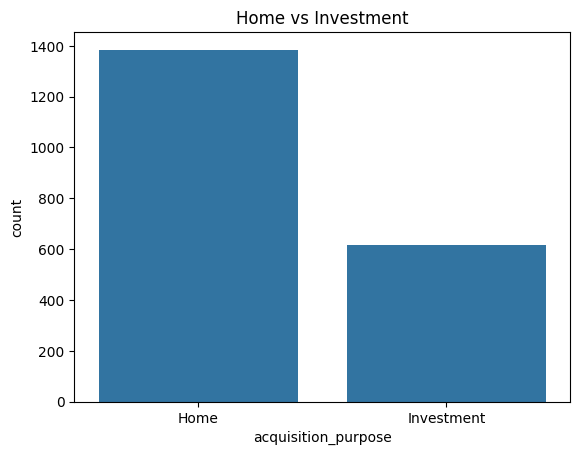

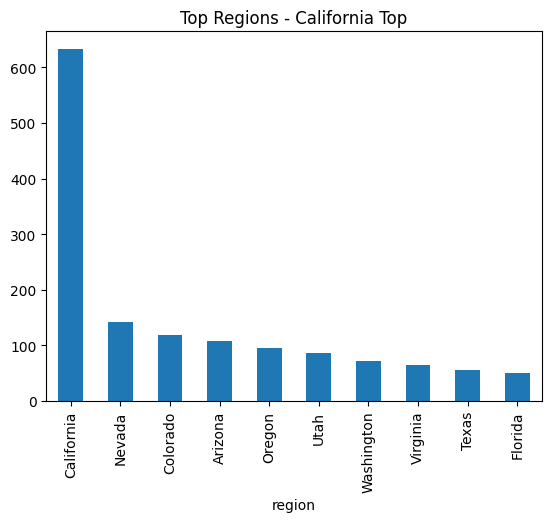

loan_applied,No,Yes
acquisition_purpose,,
Home,63.754513,36.245487
Investment,61.951220,38.048780


In [4]:
# 1. Purpose wise
sns.countplot(data=df, x='acquisition_purpose')
plt.title('Home vs Investment')
plt.show()

# 2. Region wise
df['region'].value_counts().head(10).plot(kind='bar')
plt.title('Top Regions - California Top')
plt.show()

# 3. Loan vs Purpose
pd.crosstab(df['acquisition_purpose'], df['loan_applied'], normalize='index')*100

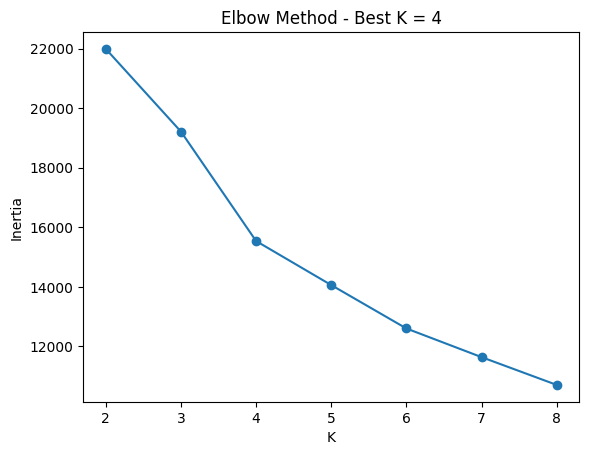

Silhouette: 0.21823900738163937
         count  avg_age  avg_satisfaction
cluster                                  
0          579     55.7               3.0
1          661     56.2               3.0
2          657     57.6               3.0
3          103     48.1               3.1


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# PRD Step 2 - Encoding
features = pd.get_dummies(df[['client_type','gender','acquisition_purpose',
                              'loan_applied','referral_channel']])

# PRD Step 3 - Scaling
features['age'] = df['age']
features['satisfaction_score'] = df['satisfaction_score']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# PRD Step 5 - Elbow Method
inertia = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2,9), inertia, marker='o')
plt.title('Elbow Method - Best K = 4')
plt.xlabel('K'); plt.ylabel('Inertia')
plt.show()

# Final Model K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
df['cluster'] = kmeans.labels_
print("Silhouette:", silhouette_score(X_scaled, df['cluster']))

# PRD Step 6 - Interpretation
print(df.groupby('cluster').agg(
    count=('client_id','count'),
    avg_age=('age','mean'),
    avg_satisfaction=('satisfaction_score','mean')
).round(1))

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clients.csv')
print(df.shape)
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], format='mixed')
df['age'] = 2026 - df['date_of_birth'].dt.year

(2000, 12)


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = pd.get_dummies(df[['client_type','gender','acquisition_purpose','loan_applied','referral_channel']])
features['age'] = df['age']
features['satisfaction_score'] = df['satisfaction_score']

X_scaled = StandardScaler().fit_transform(features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
df['cluster'] = kmeans.labels_
print("Silhouette:", silhouette_score(X_scaled, df['cluster']))
print(df.groupby('cluster')[['age','satisfaction_score']].mean().round(1))
df.to_csv('segmented_clients.csv', index=False)

Silhouette: 0.21823900738163937
          age  satisfaction_score
cluster                          
0        55.7                 3.0
1        56.2                 3.0
2        57.6                 3.0
3        48.1                 3.1


In [12]:
cluster_names_correct = {
    0: 'Global Investors',
    1: 'First-Time Buyers',
    2: 'Luxury Investors',
    3: 'Corporate Buyers'
}
df['segment'] = df['cluster'].map(cluster_names_correct)
df.to_csv('segmented_clients.csv', index=False)
print(df['segment'].value_counts())
print("Corrected & Saved!")

segment
First-Time Buyers    661
Luxury Investors     657
Global Investors     579
Corporate Buyers     103
Name: count, dtype: int64
Corrected & Saved!
